# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [2]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 2: the graph with nine vertices

Varying ground-truth $\mu$ (Section 5.2, Figure 4): a $3 \times 3$ grid with $|B| = 3$ (the top row), $|X\setminus B| = 6$, $w_{xy} = 1$, $\mu_x = \deg(x)$, $T = 9$. Paper FRNE: $0.188348\%$.

Here $\mu_x = \deg(x) = \sum_y w_{xy}$, so Assumption 1 (ii) holds with equality and $p_{xx} = 0$: the walk never stays put. This is the simple random walk (normalized Laplacian).

In [3]:
grid2    = GridGraph.make_grid(3, 3)
B2_coord = [(0, 0), (1, 2), (2, 1)]
w2       = 1.0
mu2_kind = "deg"
mu2_val  = 1.0
T2       = 10
N2       = 10**6
seed2    = 0

|X| = 9, |B| = 3, T = 10, t_max = 19


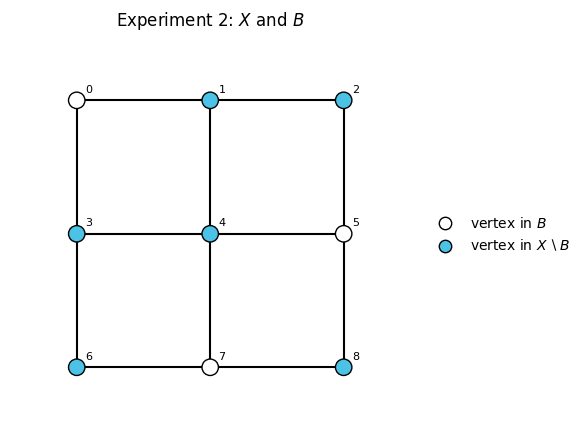

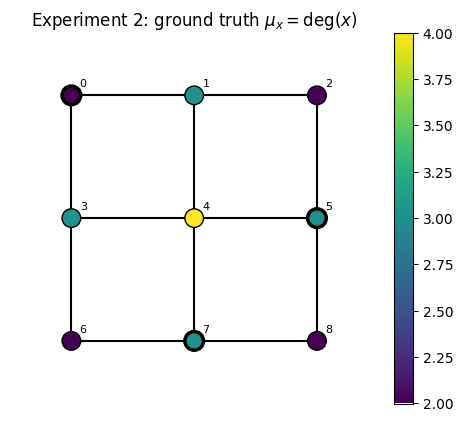

In [4]:
G2 = GridGraph(grid2, B2_coord, w=w2, mu=mu2_kind, mu_val=mu2_val)
W2, mu2, B2 = G2.W, G2.mu, G2.B
P2 = G2.transition_matrix()
t_max2 = 2 * T2 - 1
print(f"|X| = {len(mu2)}, |B| = {len(B2)}, T = {T2}, t_max = {t_max2}")

plot_graph(grid2, B2, title="Experiment 2: $X$ and $B$")
plot_graph(grid2, B2, values=mu2, title=r"Experiment 2: ground truth $\mu_x = \deg(x)$")
plt.show()

In [5]:
r2 = exact_first_passage_literal(P2, B2, t_max2)
r2_emp = empirical_first_passage(P2, B2, t_max2, n_walks=N2, seed=seed2)

summarize(P2, B2, r2_emp, r2, paper_frne=0.188348)

data shape (2T-1, |B|, |B|): (19, 3, 3)
FRNE = 0.230846%   (paper: 0.188348%)
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.7876 0.8383 0.8383]
 [0.7001 0.8936 0.8568]
 [0.7001 0.8568 0.8936]]
probability mass observed by t = 2T-1 (empirical):
 [[0.787  0.838  0.8382]
 [0.7005 0.894  0.8564]
 [0.6989 0.8566 0.8929]]


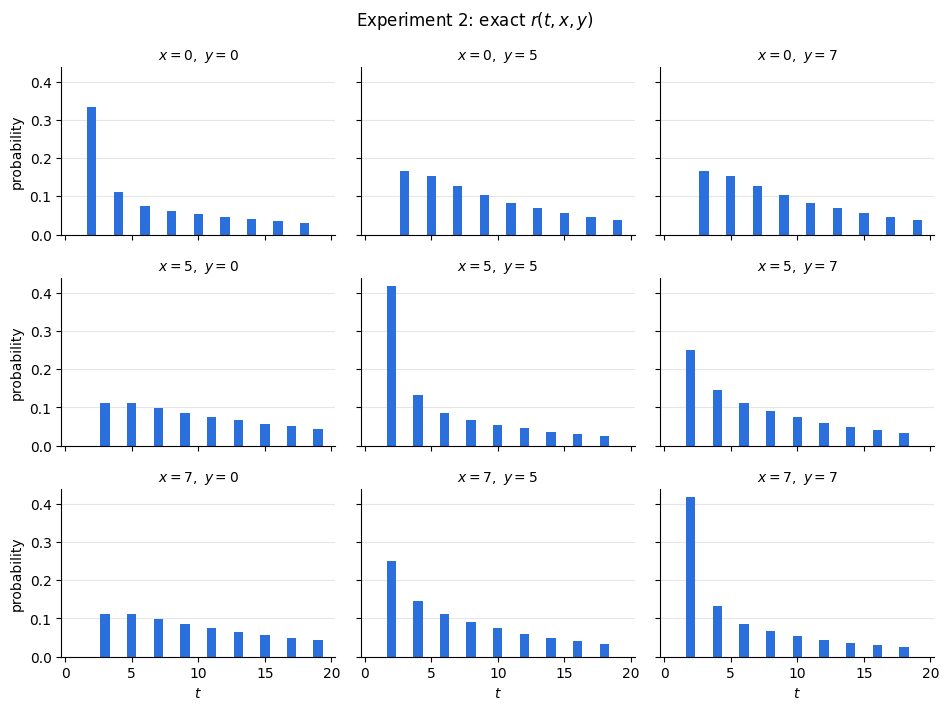

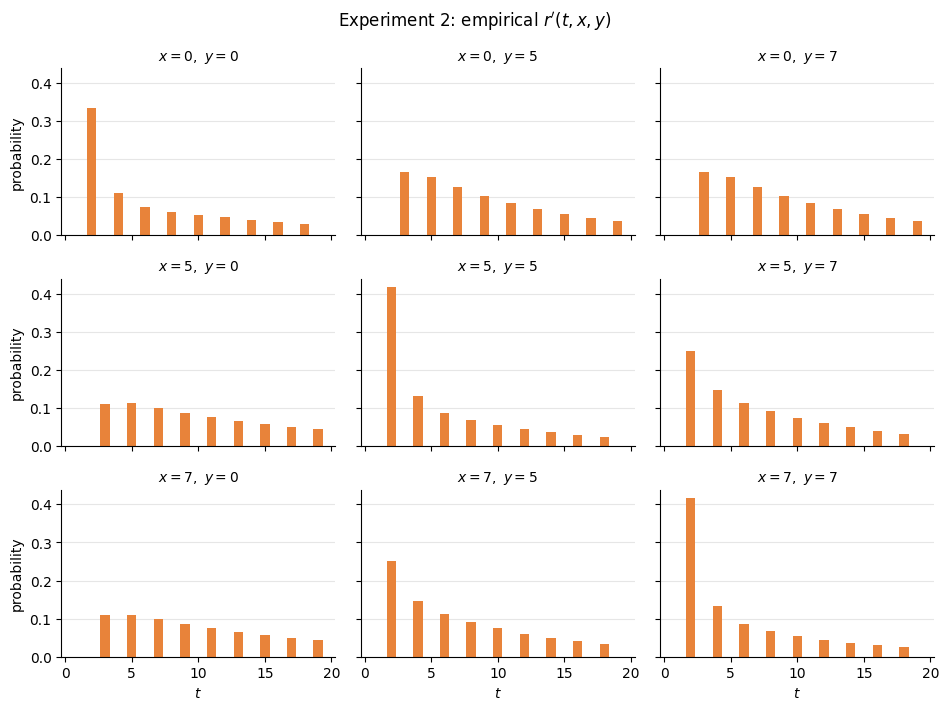

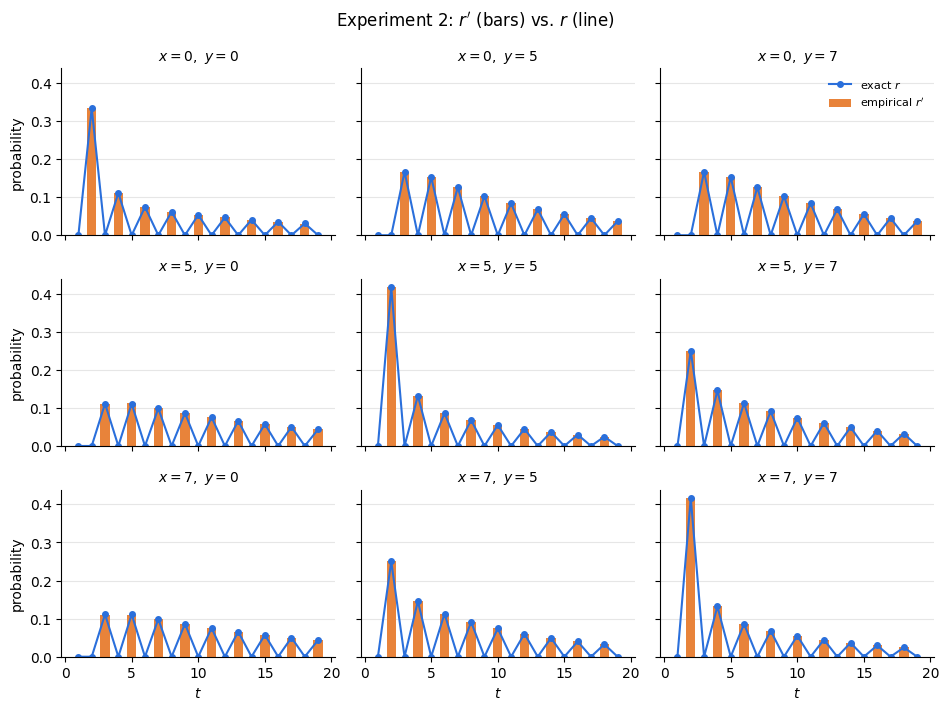

In [6]:
plot_exact_distribution(r2, B2, title="Experiment 2: exact $r(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, title="Experiment 2: empirical $r'(t, x, y)$")
plot_empirical_distribution(r2_emp, B2, r=r2, title="Experiment 2: $r'$ (bars) vs. $r$ (line)")
plt.show()

|B| = 1: FRNE = 0.219393%
|B| = 2: FRNE = 0.196226%
|B| = 3: FRNE = 0.234703%
|B| = 4: FRNE = 0.178759%
|B| = 5: FRNE = 0.204652%
|B| = 6: FRNE = 0.226614%
|B| = 7: FRNE = 0.224152%
|B| = 8: FRNE = 0.222931%


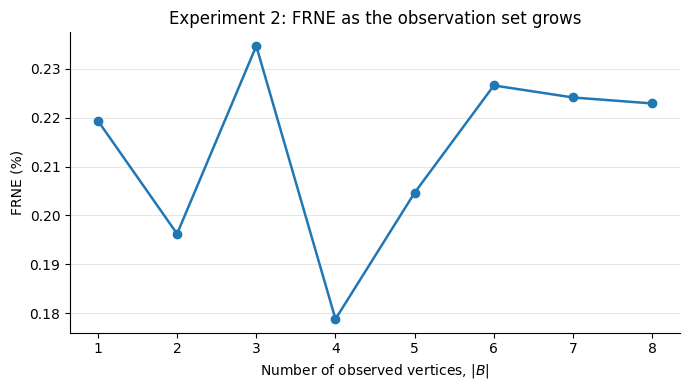

In [8]:
B2_coord = [(0, 0)]  
N2_sweep = 10**6
B2_sweep_order = B2_coord + [coord for coord in grid2 if coord not in B2_coord]
B2_sweep_sizes = list(range(1, len(grid2)))
B2_sweep_frne = []

for nB in B2_sweep_sizes:
    B_coords = B2_sweep_order[:nB]
    B_sweep = torch.tensor([G2.index[tuple(coord)] for coord in B_coords], dtype=torch.long)
    r_exact = exact_first_passage_literal(P2, B_sweep, t_max2)
    r_empirical = empirical_first_passage(
        P2, B_sweep, t_max2, n_walks=N2_sweep, batch=min(10**4, N2_sweep), seed=seed2 + nB
    )
    B2_sweep_frne.append(frne(r_exact, r_empirical))
    print(f"|B| = {nB}: FRNE = {B2_sweep_frne[-1]:.6f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(B2_sweep_sizes, B2_sweep_frne, "o-", lw=1.8)
ax.set(xticks=B2_sweep_sizes, xlabel=r"Number of observed vertices, $|B|$",
       ylabel="FRNE (%)", title="Experiment 2: FRNE as the observation set grows")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Evaluated 510 subsets.
|B|=1: best FRNE=0.979525%; vertices=[(1, 1)]; indices=(4,)
|B|=2: best FRNE=1.594164%; vertices=[(0, 2), (1, 2)]; indices=(2, 5)
|B|=3: best FRNE=1.590403%; vertices=[(0, 1), (1, 0), (2, 1)]; indices=(1, 3, 7)
|B|=4: best FRNE=1.683125%; vertices=[(0, 0), (0, 1), (1, 0), (1, 1)]; indices=(0, 1, 3, 4)
|B|=5: best FRNE=1.888543%; vertices=[(0, 2), (1, 0), (1, 1), (1, 2), (2, 1)]; indices=(2, 3, 4, 5, 7)
|B|=6: best FRNE=1.979760%; vertices=[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (2, 2)]; indices=(0, 1, 2, 3, 4, 8)
|B|=7: best FRNE=1.909285%; vertices=[(0, 0), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]; indices=(0, 3, 4, 5, 6, 7, 8)
|B|=8: best FRNE=2.024024%; vertices=[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 1), (2, 2)]; indices=(0, 1, 2, 3, 4, 5, 7, 8)
Overall best subset: {'size': 1, 'indices': (4,), 'vertices': ((1, 1),), 'frne': 0.9795254404588128}


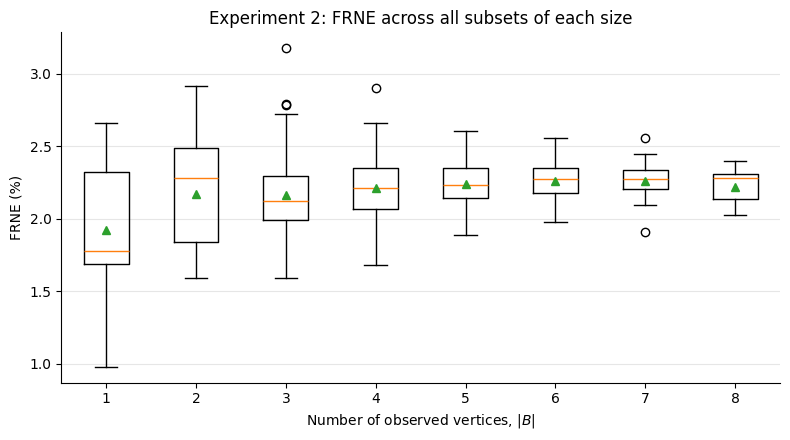

In [9]:
from itertools import combinations

N2_sweep = 10**4  # Monte Carlo walks per ordered pair, for each subset
B2_sweep_sizes = list(range(1, len(grid2)))
B2_sweep_frne = {nB: [] for nB in B2_sweep_sizes}
B2_sweep_results = []

for nB in B2_sweep_sizes:
    for vertex_indices in combinations(range(len(grid2)), nB):
        B_coords = [grid2[i] for i in vertex_indices]
        B_sweep = torch.tensor([G2.index[coord] for coord in B_coords], dtype=torch.long)
        r_exact = exact_first_passage_literal(P2, B_sweep, t_max2)
        subset_seed = seed2 + sum(1 << i for i in vertex_indices)
        r_empirical = empirical_first_passage(
            P2, B_sweep, t_max2, n_walks=N2_sweep,
            batch=min(10**4, N2_sweep), seed=subset_seed
        )
        subset_frne = frne(r_exact, r_empirical)
        B2_sweep_frne[nB].append(subset_frne)
        B2_sweep_results.append({
            "size": nB,
            "indices": vertex_indices,
            "vertices": tuple(B_coords),
            "frne": subset_frne,
        })

B2_best_by_size = {
    nB: min((result for result in B2_sweep_results if result["size"] == nB),
            key=lambda result: result["frne"])
    for nB in B2_sweep_sizes
}
B2_best_overall = min(B2_sweep_results, key=lambda result: result["frne"])

print(f"Evaluated {len(B2_sweep_results)} subsets.")
for nB, result in B2_best_by_size.items():
    print(f"|B|={nB}: best FRNE={result['frne']:.6f}%; "
          f"vertices={list(result['vertices'])}; indices={result['indices']}")
print("Overall best subset:", B2_best_overall)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([B2_sweep_frne[nB] for nB in B2_sweep_sizes],
           positions=B2_sweep_sizes, showmeans=True)
ax.set_xticks(B2_sweep_sizes)
ax.set_xlabel(r"Number of observed vertices, $|B|$")
ax.set_ylabel("FRNE (%)")
ax.set_title("Experiment 2: FRNE across all subsets of each size")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()